# Slip transfer factor $\chi$ across a grain boundary

$\chi = \cos\hat{\alpha}\cdot\cos\hat{\delta}$ (Jiménez et al., Scripta Mater. 162 (2019) 261; Beyerlein et al., JOM 64 (2012) 1192).

- $\hat{\alpha}$: twist angle between the traces of the incoming and outgoing slip planes on the grain boundary plane
- $\hat{\delta}$: angle between the incoming and outgoing slip directions

The helper functions live in `chi_factor_example.py`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.transform import Rotation
from chi_factor_example import fcc_slip_systems, outgoing_chi, schmid

## Inputs
Edit these and re-run the cells below.

In [2]:
incoming_index = 0            # 0-11, incoming FCC {111}<110> system in grain 1
euler = [30, 40, 20]          # Bunge ZXZ angles (deg) of grain 2 relative to grain 1
gb_normal = np.array([1.0, 0.0, 0.0])
load = np.array([0.0, 0.0, 1.0])  # loading direction for the Schmid factor

gb_normal = gb_normal / np.linalg.norm(gb_normal)
rotation = Rotation.from_euler('ZXZ', euler, degrees=True)
systems = fcc_slip_systems()
values = outgoing_chi(systems[incoming_index], rotation, gb_normal)  # columns: chi, alpha, delta
schmid_out = np.array([schmid(rotation.apply(n), rotation.apply(d), load) for n, d in systems])
order = np.argsort(values[:, 0])[::-1]
best = order[0]
print(f'Best outgoing system {best}: chi={values[best, 0]:.3f}, alpha={values[best, 1]:.1f} deg, delta={values[best, 2]:.1f} deg')

Best outgoing system 1: chi=0.784, alpha=24.6 deg, delta=30.5 deg


## Ranking of outgoing systems

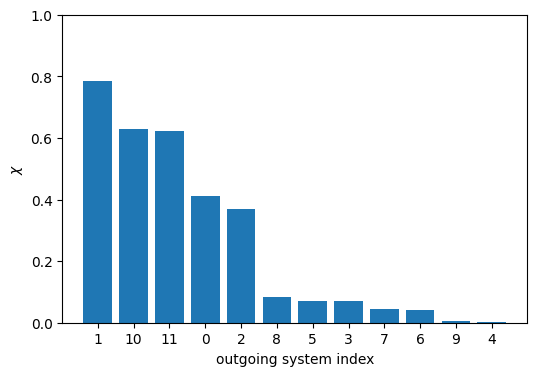

In [3]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(range(12), values[order, 0])
ax.set_xticks(range(12), [str(i) for i in order])
ax.set(xlabel='outgoing system index', ylabel=r'$\chi$', ylim=(0, 1))
plt.show()

## $\alpha$ vs $\delta$ and $\chi$ vs Schmid factor
Dashed lines mark the 45° limits below which cracks were observed to propagate.

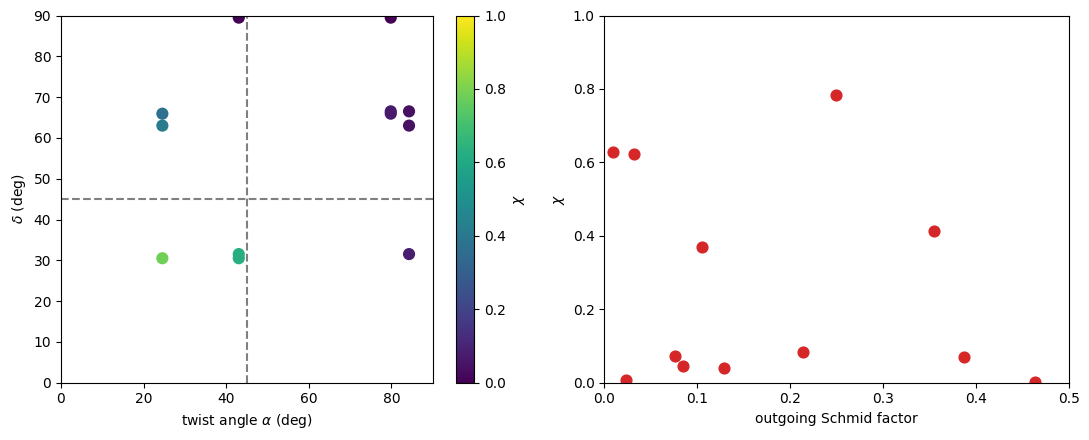

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
sc = axes[0].scatter(values[:, 1], values[:, 2], c=values[:, 0], cmap='viridis', vmin=0, vmax=1, s=60)
axes[0].axvline(45, color='grey', ls='--')
axes[0].axhline(45, color='grey', ls='--')
axes[0].set(xlim=(0, 90), ylim=(0, 90), xlabel=r'twist angle $\alpha$ (deg)', ylabel=r'$\delta$ (deg)')
fig.colorbar(sc, ax=axes[0], label=r'$\chi$')
axes[1].scatter(schmid_out, values[:, 0], s=60, color='tab:red')
axes[1].set(xlabel='outgoing Schmid factor', ylabel=r'$\chi$', xlim=(0, 0.5), ylim=(0, 1))
plt.tight_layout()
plt.show()

## Comparison with Jiménez et al. (2019)

The paper (IN718, 12 grain boundaries, 4 candidate outgoing slip planes per boundary, Fig. 4) gives no tabulated data, so the comparison is **qualitative** and uses 12 randomly oriented FCC grain pairs (48 candidate planes, like the paper):

- observed crack paths have $\alpha<45^\circ$ and $\delta<45^\circ$;
- observed paths have $\chi \approx 0.6$-$0.95$, whatever the Schmid factor (0-0.45);
- non-propagated candidate planes spread over $\chi \approx 0$-$0.7$.

For each random boundary we take the incoming system, then for each of the 4 outgoing {111} planes the slip direction with minimum $\delta$ (as in the paper), and keep the plane with the highest $\chi$ as the predicted crack path.

In [5]:
from chi_factor_example import acute_angle

rng = np.random.default_rng(0)
systems = fcc_slip_systems()
plane_ids = [list(range(3 * p, 3 * p + 3)) for p in range(4)]  # systems are grouped by plane

def tilt_angle(n1, n2, n_gb):
    """beta: angle between plane normals after rotating plane 2 about the GB normal to remove the twist."""
    t1, t2 = np.cross(n1, n_gb), np.cross(n2, n_gb)
    theta = np.arctan2(n_gb @ np.cross(t2, t1), t2 @ t1)
    theta -= np.pi * np.round(theta / np.pi)  # traces are lines: use the smallest rotation
    return acute_angle(n1, Rotation.from_rotvec(theta * n_gb).apply(n2))

rows = []  # (boundary, chi, alpha, beta, gamma, delta, m_delta, is_best)
n_boundaries = 12  # same number of boundaries as in the paper (12 x 4 = 48 points)
for b in range(n_boundaries):
    rot = Rotation.random(random_state=int(rng.integers(1 << 31)))
    n_gb = rng.normal(size=3); n_gb /= np.linalg.norm(n_gb)
    inc = systems[int(rng.integers(12))]
    res = outgoing_chi(inc, rot, n_gb)
    cand = []
    for ids in plane_ids:
        k = ids[int(np.argmin(res[ids, 2]))]  # minimum delta within the plane
        n2, d2 = systems[k]
        m_all = [schmid(rot.apply(systems[i][0]), rot.apply(systems[i][1]), load) for i in ids]
        d_hs = rot.apply(systems[ids[int(np.argmax(m_all))]][1])  # highest-Schmid-factor direction of the plane
        beta = tilt_angle(inc[0], rot.apply(n2), n_gb)
        gamma = acute_angle(inc[1], d_hs)
        cand.append((res[k, 0], res[k, 1], beta, gamma, res[k, 2], schmid(rot.apply(n2), rot.apply(d2), load)))
    best = int(np.argmax([c[0] for c in cand]))
    rows += [(b, *c, i == best) for i, c in enumerate(cand)]

data = np.array(rows, dtype=float)
chi, alpha, beta, gamma, delta, sf = data[:, 1:7].T
is_best = data[:, 7].astype(bool)
print(f'chi range: {chi.min():.2f} - {chi.max():.2f} (expected within [0, 1])')
print(f'predicted paths with alpha<45 and delta<45: {np.mean((alpha[is_best] < 45) & (delta[is_best] < 45)):.0%}')
print(f'other planes with alpha<45 and delta<45:    {np.mean((alpha[~is_best] < 45) & (delta[~is_best] < 45)):.0%}')
print(f'median chi: predicted path {np.median(chi[is_best]):.2f}, other planes {np.median(chi[~is_best]):.2f}')

chi range: 0.03 - 0.94 (expected within [0, 1])
predicted paths with alpha<45 and delta<45: 92%
other planes with alpha<45 and delta<45:    19%
median chi: predicted path 0.88, other planes 0.42


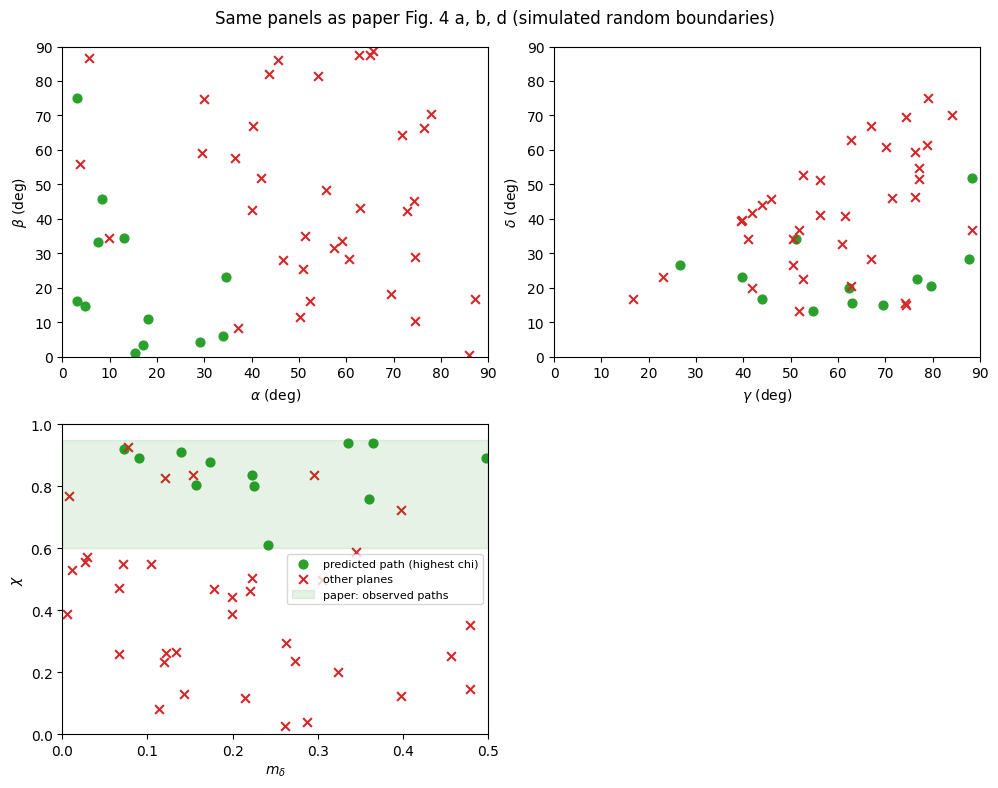

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
panels = [(alpha, beta, r'$\alpha$ (deg)', r'$\beta$ (deg)'), (gamma, delta, r'$\gamma$ (deg)', r'$\delta$ (deg)'),
          (sf, chi, r'$m_\delta$', r'$\chi$')]
for ax, (x, y, xl, yl) in zip(axes.flat, panels):
    for mask, color, marker, label in [(is_best, 'tab:green', 'o', 'predicted path (highest chi)'), (~is_best, 'tab:red', 'x', 'other planes')]:
        ax.scatter(x[mask], y[mask], s=40, c=color, marker=marker, label=label)
    ax.set(xlabel=xl, ylabel=yl)
    if x is not sf: ax.set(xlim=(0, 90), ylim=(0, 90))
axes[1, 0].set(xlim=(0, 0.5), ylim=(0, 1))
axes[1, 0].axhspan(0.6, 0.95, color='green', alpha=0.1, label='paper: observed paths')
axes[1, 0].legend(fontsize=8)
axes[1, 1].axis('off')
fig.suptitle('Same panels as paper Fig. 4 a, b, d (simulated random boundaries)')
plt.tight_layout(); plt.show()

**How to read it.** Green circles are the predicted crack paths (one per boundary), red crosses the other candidate planes. The three panels mirror Fig. 4 a ($\beta$ vs $\alpha$), b ($\delta$ vs $\gamma$) and d ($\chi$ vs $m_\delta$). Because green is chosen by $\chi$ (not observed), the separation is expected and only checks the formula; in the paper, $\alpha$, $\beta$, $\gamma$ and $\delta$ taken individually do not separate the observed paths. With only 12 random boundaries the exact numbers change with the seed. Quantitative validation would require the paper's per-boundary orientations and crack observations.